In [1]:
#Data Handling
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

#Charts
import matplotlib.pyplot as plt
import seaborn as sns

#Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score, permutation_test_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier, BernoulliRBM
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             silhouette_score, adjusted_rand_score)
from xgboost import XGBClassifier
import shap

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   #Fixed number so we get the same results every time we run
TARGETS = ["Surgery_Performed", "Radiation_Treatment", "Chemotherapy"]   #The three treatments we predict

## Step 2: Load the data

We read the CSV file into a table called df (short for "data frame") and look at the first 5 rows.

In [2]:
df = pd.read_csv("brain_tumor_dataset.csv")
df.head()

,Patient_ID,Age,Gender,Tumor_Type,Tumor_Size,Location,Histology,Stage,Symptom_1,Symptom_2,Symptom_3,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,Family_History,MRI_Result,Follow_Up_Required
0,1,73,Male,Malignant,5.375612,Temporal,Astrocytoma,III,Vision Issues,Seizures,Seizures,No,No,No,51.312579,0.111876,No,Positive,Yes
1,2,26,Male,Benign,4.847098,Parietal,Glioblastoma,II,Headache,Headache,Nausea,Yes,Yes,Yes,46.373273,2.165736,Yes,Positive,Yes
2,3,31,Male,Benign,5.588391,Parietal,Meningioma,I,Vision Issues,Headache,Seizures,No,No,No,47.072221,1.884228,No,Negative,No
3,4,29,Male,Malignant,1.436600,Temporal,Medulloblastoma,IV,Vision Issues,Seizures,Headache,Yes,No,Yes,51.853634,1.283342,Yes,Negative,No
4,5,54,Female,Benign,2.417506,Parietal,Glioblastoma,I,Headache,Headache,Seizures,No,No,Yes,54.708987,2.069477,No,Positive,Yes


# Part B: Comparison with the paper

## Step 11: Repeating the paper's method

To compare fairly we also repeat the paper's exact method (its Sections 2.3 and 2.4): label encoding, scaling, the other two treatments kept as inputs, an 80/20 stratified split and the same nine models, each tuned with a grid search using 10-fold cross-validation. If we used only our own methods, a different result could simply be blamed on the different method.

| Model | Idea in one line |
|---|---|
| Logistic Regression | A weighted sum of the columns turned into a probability |
| k-Nearest Neighbours | Looks at the most similar patients and takes a vote |
| Support Vector Machine | Draws the best boundary between Yes and No |
| Naive Bayes | Uses probabilities, assumes the columns are independent |
| Decision Tree | Flowchart of yes/no questions |
| Random Forest | Many decision trees that vote together |
| Gradient Boosting | Trees built one after another, each fixing the last one's mistakes (the paper's best model) |
| AdaBoost | Like boosting, gives more weight to the patients it got wrong |
| XGBoost | A fast, popular version of gradient boosting |

The paper does not list its grid values so these are reasonable choices. This step takes several minutes to run.

In [18]:
#The paper's preparation
p = df.drop(columns=["Patient_ID", "Survival_Rate", "Follow_Up_Required"]).copy()
for col in p.select_dtypes(exclude="number").columns:
    p[col] = LabelEncoder().fit_transform(p[col])
scale_cols = ["Age", "Tumor_Size", "Tumor_Growth_Rate"]
p[scale_cols] = StandardScaler().fit_transform(p[scale_cols])

def get_data(task):
    #Inputs and answer for one treatment (other treatments kept, as in the paper), then the 80/20 stratified split
    X, y = p.drop(columns=[task]), p[task]
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

MODELS = {
    "Logistic Regression": (LogisticRegression(max_iter=2000), {"C": [0.1, 1, 10]}),
    "K-Nearest Neighbors": (KNeighborsClassifier(), {"n_neighbors": [3, 5, 7, 9]}),
    "Support Vector Machine": (SVC(kernel="rbf", cache_size=1000), {"C": [1]}),
    "Naive Bayes": (GaussianNB(), {"var_smoothing": [1e-9, 1e-8, 1e-7]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {"max_depth": [3, 5, None]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE), {"n_estimators": [100], "max_depth": [5, None]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3]}),
    "AdaBoost": (AdaBoostClassifier(random_state=RANDOM_STATE), {"n_estimators": [50, 100], "learning_rate": [0.5, 1.0]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE),
                {"n_estimators": [100, 200], "max_depth": [3, 5], "learning_rate": [0.1]}),
}
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

def scores_of(model, X):
    #Probability of Yes (or a score for models without probabilities) for AUC
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

rows, best_gb = [], {}
for task in TARGETS:
    X_tr, X_te, y_tr, y_te = get_data(task)
    for name, (model, grid) in MODELS.items():
        best = GridSearchCV(model, grid, cv=cv10, scoring="roc_auc", n_jobs=-1).fit(X_tr, y_tr).best_estimator_
        pred = best.predict(X_te)
        rows.append({"Treatment": task, "Model": name, "AUC": roc_auc_score(y_te, scores_of(best, X_te)),
                     "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
                     "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred)})
        if name == "Gradient Boosting":
            best_gb[task] = (best, X_te)
    print(f"{task} done")

results = pd.DataFrame(rows).round(3)
print("Accuracy range:", results["Accuracy"].min(), "to", results["Accuracy"].max())
print("AUC range:", results["AUC"].min(), "to", results["AUC"].max())
results.pivot(index="Model", columns="Treatment", values="AUC")

Surgery_Performed done


Radiation_Treatment done


Chemotherapy done
Accuracy range: 0.483 to 0.522
AUC range: 0.488 to 0.529


Treatment,Chemotherapy,Radiation_Treatment,Surgery_Performed
Model,,,
AdaBoost,0.514,0.500,0.491
Decision Tree,0.529,0.502,0.496
Gradient Boosting,0.512,0.493,0.507
K-Nearest Neighbors,0.509,0.499,0.506
Logistic Regression,0.509,0.495,0.496
Naive Bayes,0.511,0.494,0.488
Random Forest,0.503,0.491,0.490
Support Vector Machine,0.511,0.493,0.490
XGBoost,0.504,0.488,0.506


**Result:** With the paper's own method every model still scores an AUC of about 0.50 and an accuracy of about 50% for all three treatments, the same as our approach and the same as guessing.

## Step 12: SHAP (which columns does the model use?)

Like the paper we explain Gradient Boosting with SHAP values. SHAP shows how much each column pushes the prediction up or down. We show the average size of each column's effect as a percentage.

Surgery_Performed top 3: ['Tumor_Size', 'Tumor_Growth_Rate', 'Age']
Radiation_Treatment top 3: ['Tumor_Size', 'Tumor_Growth_Rate', 'Stage']


Chemotherapy top 3: ['Tumor_Size', 'Tumor_Growth_Rate', 'Age']


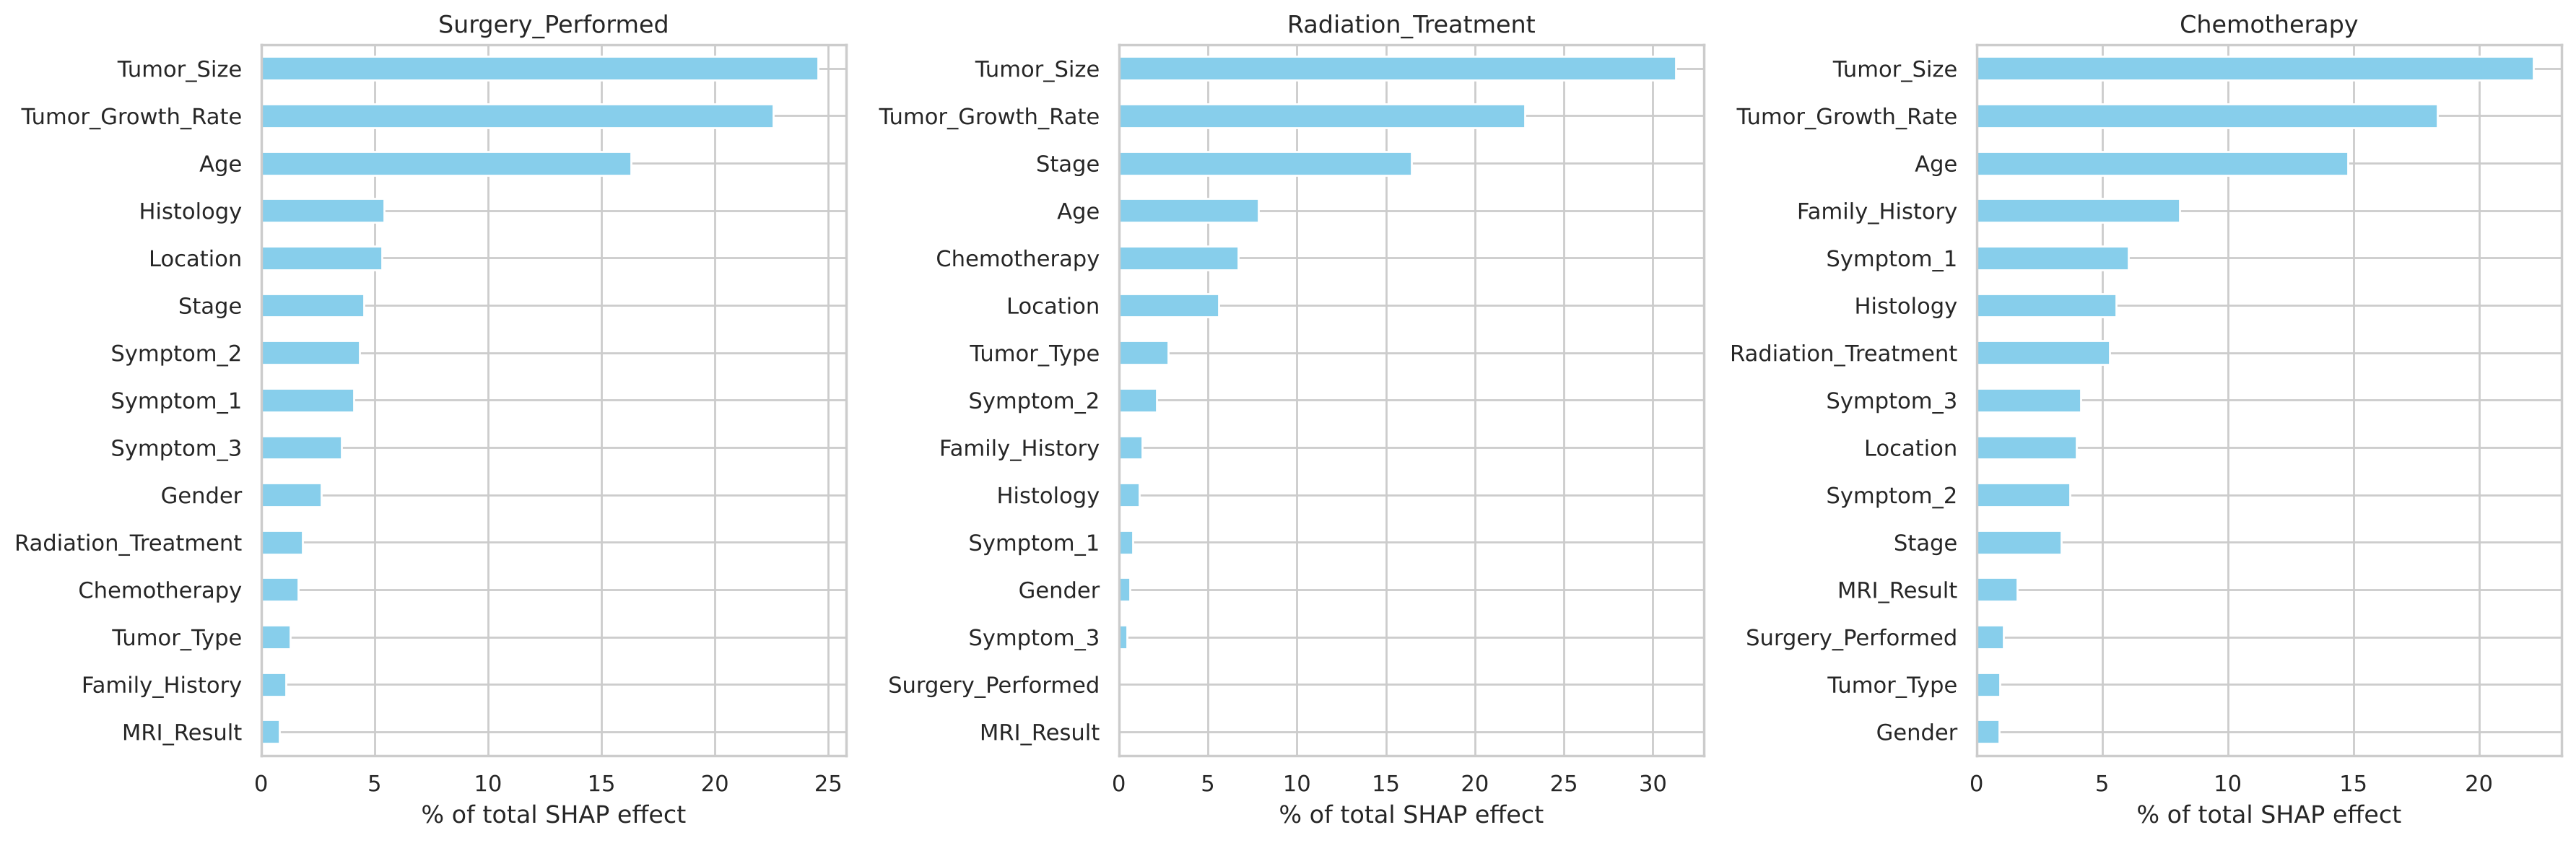

In [19]:
#Average SHAP effect of each column for each treatment (Gradient Boosting)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, task in zip(axes, TARGETS):
    model, X_te = best_gb[task]
    sv = shap.TreeExplainer(model).shap_values(X_te)
    pct = pd.Series(np.abs(sv).mean(axis=0), index=X_te.columns)
    pct = (100 * pct / pct.sum()).sort_values()
    pct.plot(kind="barh", ax=ax, color="#87CEEB")
    ax.set_title(task); ax.set_xlabel("% of total SHAP effect")
    print(task, "top 3:", list(pct.index[::-1][:3]))
plt.tight_layout()
plt.show()

**Result:** Like the paper SHAP ranks tumour size and growth rate near the top. But the model behind it scores only about 0.50 so this does not show a real effect. Tree models have many more places to split a number column than a category column, so number columns get used more even when they are just noise.

## Step 13: Comparing the metrics with the paper

The paper reports these values for its best model, Gradient Boosting (Figure 2 of the paper).

In [20]:
#Paper's Gradient Boosting values next to ours
paper = pd.DataFrame({"Treatment": TARGETS, "Paper AUC": [0.85, 0.91, 0.90], "Paper accuracy": [0.84, 0.88, 0.86]})
ours = results[results["Model"] == "Gradient Boosting"][["Treatment", "AUC", "Accuracy"]]
ours = ours.rename(columns={"AUC": "Paper's method: our AUC", "Accuracy": "Paper's method: our accuracy"})
nn_best = nn_table.groupby("Treatment")["Test AUC"].max().rename("Our approach: best neural network AUC")
paper.merge(ours, on="Treatment").merge(nn_best, on="Treatment")

,Treatment,Paper AUC,Paper accuracy,Paper's method: our AUC,Paper's method: our accuracy,Our approach: best neural network AUC
0,Surgery_Performed,0.85,0.84,0.507,0.498,0.504
1,Radiation_Treatment,0.91,0.88,0.493,0.488,0.509
2,Chemotherapy,0.90,0.86,0.512,0.514,0.517


**Result:** Both the paper's method and our approach give about 0.50 instead of 0.85 to 0.91. We could not reproduce the paper's results.

## Step 14: Why are the paper's scores so high? (Training vs test AUC)

A model should always be scored on new patients it has never seen (the test set). If you score it on the patients it learned from (the training set) it can look much better than it really is because it has memorised them. The paper does not say which set its scores come from, so we test both.

In [21]:
#Score each model on data it has seen (training) and on new data (test)
rows = []
for task in TARGETS:
    X_tr, X_te, y_tr, y_te = get_data(task)
    for name, m in {"Gradient Boosting (300 trees, depth 5)": GradientBoostingClassifier(n_estimators=300, max_depth=5, random_state=RANDOM_STATE),
                    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5)}.items():
        m.fit(X_tr, y_tr)
        rows.append({"Treatment": task, "Model": name,
                     "AUC on training data": roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1]),
                     "AUC on test data": roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])})
pd.DataFrame(rows).round(3)

,Treatment,Model,AUC on training data,AUC on test data
0,Surgery_Performed,"Gradient Boosting (300 trees, depth 5)",0.884,0.503
1,Surgery_Performed,k-NN (k=5),0.743,0.505
2,Radiation_Treatment,"Gradient Boosting (300 trees, depth 5)",0.889,0.502
3,Radiation_Treatment,k-NN (k=5),0.741,0.499
4,Chemotherapy,"Gradient Boosting (300 trees, depth 5)",0.887,0.490
5,Chemotherapy,k-NN (k=5),0.746,0.509


**Result:** On the training data Gradient Boosting reaches a high AUC close to the paper's 0.85 to 0.91 but on the test data it drops to about 0.50. So numbers like the paper's could come from scoring on training data (or another kind of leakage). We cannot be sure without the authors' code.

## Step 15: Conclusion

| Measure | Value |
|---|---|
| Baseline (guessing) | AUC 0.50 |
| Our approach: three neural networks (no leakage, one-hot) | about 0.50 |
| Our approach: all three treatments together | about guessing level |
| Permutation test p-values | above 0.05 |
| Paper's method repeated: nine models | about 0.50 |
| Paper's reported Gradient Boosting AUC | 0.85 to 0.91 |
| Gradient Boosting AUC on training data | close to the paper |

**What we found**
- The data is clean and balanced but EDA and clustering show no link between the patient details and the treatments.
- Our approach (no leakage, one-hot encoding, three neural networks, predicting treatments together) scores about 0.50. The permutation test shows this is consistent with chance and the sanity check proves our code works.
- Repeating the paper's method also gives about 0.50 so we could not reproduce its results. Scoring on training data gives numbers close to the paper's which is a likely explanation.

**Why?** The Kaggle page says the data is simulated. The values look randomly generated so there is no real pattern to learn.

**What this means for our project:** in this dataset patient records alone cannot guide treatment decisions, while our MRI image models reach high accuracy, so the useful information comes from the images.

**Future work:** use real hospital records linked to MRI scans, with a clear record of where the data came from and with code shared so others can check it.